In [ ]:
import pandas as pd
import zipfile

# Open the zip file and read a specific CSV file
zip_path = "/content/archive (8).zip"
with zipfile.ZipFile(zip_path, 'r') as z:
    # Reading 'train.csv' as an example; you can change this to 'test.csv' or 'Sample_Submission.csv'
    with z.open('train.csv') as f:
        df = pd.read_csv(f)

df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import re

In [ ]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [ ]:
df.shape

(45593, 20)

In [ ]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000



Missing Values:
ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64

Duplicate Values:
0


In [ ]:


df.columns = df.columns.str.strip()

df.drop_duplicates(inplace=True)

# Replace invalid missing-value strings
df.replace(
    ["NaN", "nan", "NULL", "null", ""],
    np.nan,
    inplace=True
)

# Convert target column to numeric
df["Time_taken(min)"] = pd.to_numeric(
    df["Time_taken(min)"]
    .astype(str)
    .str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df.dropna(
    subset=["Time_taken(min)"],
    inplace=True
)

print("Data Cleaning Completed")

print(df.isnull().sum())

Data Cleaning Completed
ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64


In [ ]:


df["order_hour"] = pd.to_datetime(
    df["Time_Orderd"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

missing_hour = df["order_hour"].isna()

df.loc[missing_hour, "order_hour"] = pd.to_datetime(
    df.loc[missing_hour, "Time_Orderd"],
    format="%H:%M",
    errors="coerce"
).dt.hour



def calculate_distance(row):

    lat1 = row["Restaurant_latitude"]
    lon1 = row["Restaurant_longitude"]

    lat2 = row["Delivery_location_latitude"]
    lon2 = row["Delivery_location_longitude"]

    if pd.isna([lat1, lon1, lat2, lon2]).any():
        return np.nan

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    distance = 6371 * 2 * np.arcsin(np.sqrt(a))

    return distance

df["distance_km"] = df.apply(
    calculate_distance,
    axis=1
)

print("Feature Engineering Completed")

display(
    df[["order_hour", "distance_km"]].head()
)

Feature Engineering Completed


,order_hour,distance_km
0,11.0,3.025149
1,19.0,20.183530
2,8.0,1.552758
3,18.0,7.790401
4,13.0,6.210138


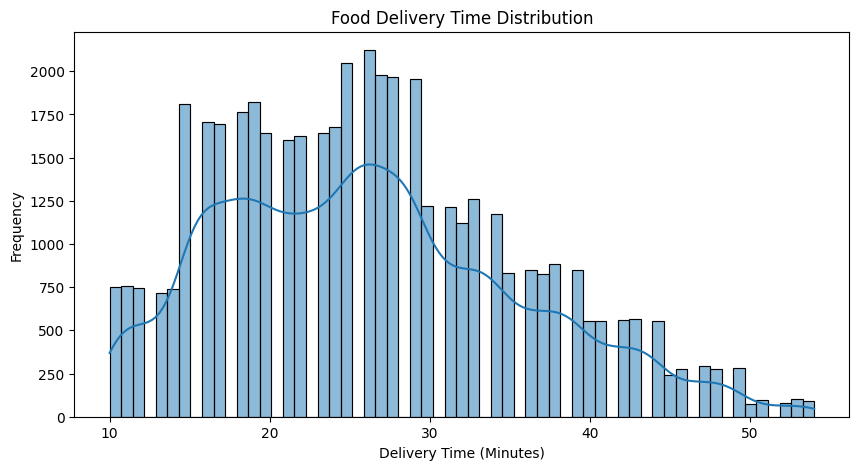

In [ ]:


plt.figure(figsize=(10,5))

sns.histplot(
    df["Time_taken(min)"],
    kde=True
)

plt.title("Food Delivery Time Distribution")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Frequency")

plt.show()

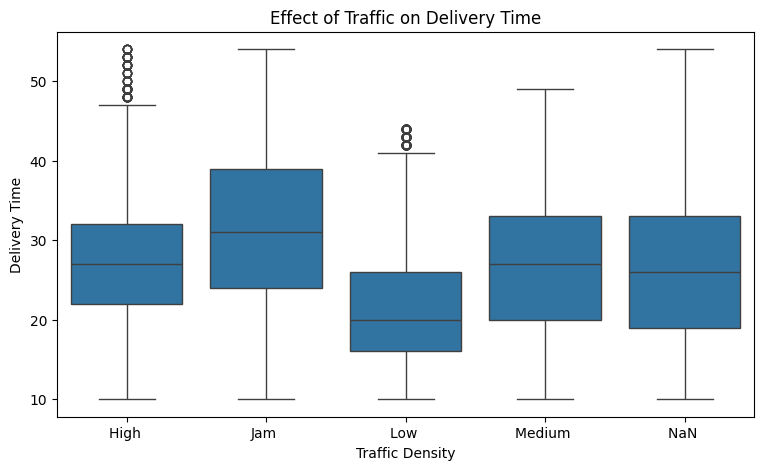

In [ ]:


plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="Road_traffic_density",
    y="Time_taken(min)"
)

plt.title("Effect of Traffic on Delivery Time")
plt.xlabel("Traffic Density")
plt.ylabel("Delivery Time")

plt.show()

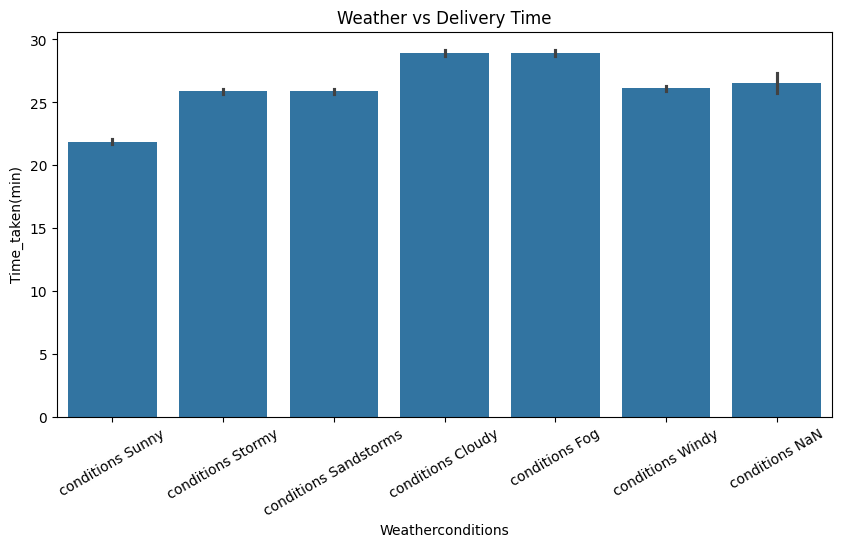

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="Weatherconditions",
    y="Time_taken(min)"
)

plt.title("Weather vs Delivery Time")
plt.xticks(rotation=30)

plt.show()

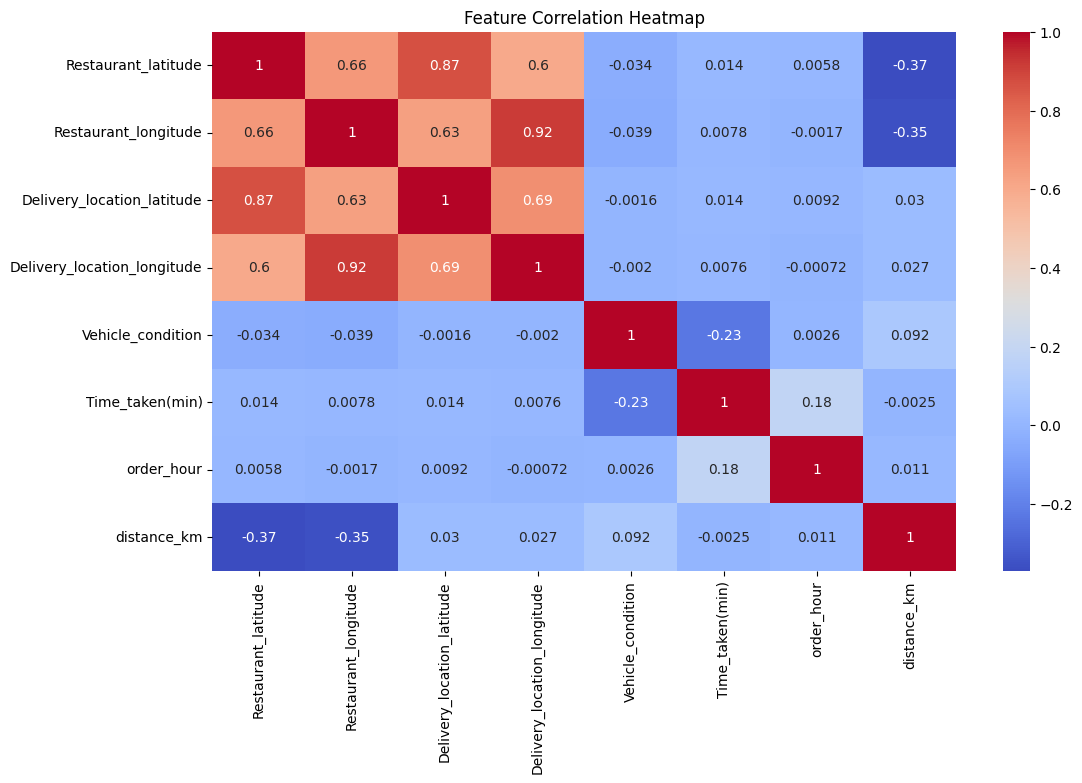

In [ ]:


numeric_df = df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12,7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
numeric_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "order_hour",
    "distance_km"
]

categorical_features = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "City"
]

features = numeric_features + categorical_features

X = df[features].copy()

y = df["Time_taken(min)"].copy()

for col in numeric_features:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Delivery_person_Age  Delivery_person_Ratings  Vehicle_condition  \
0                 37.0                      4.9                  2   
1                 34.0                      4.5                  2   
2                 23.0                      4.4                  0   
3                 38.0                      4.7                  0   
4                 32.0                      4.6                  1   

   multiple_deliveries  order_hour  distance_km      Weatherconditions  \
0                  0.0        11.0     3.025149       conditions Sunny   
1                  1.0        19.0    20.183530      conditions Stormy   
2                  1.0         8.0     1.552758  conditions Sandstorms   
3                  1.0        18.0     7.790401       conditions Sunny   
4                  1.0        13.0     6.210138      conditions Cloudy   

  Road_traffic_density Type_of_order Type_of_vehicle            City  
0                High         Snack      motorc

In [ ]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Completed")

Preprocessing Completed


In [ ]:


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (36474, 11)
Testing Data: (9119, 11)


In [ ]:


from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

print("Machine Learning Algorithms Imported")

Machine Learning Algorithms Imported


In [ ]:


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = {}

for name, algorithm in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    trained_models[name] = pipeline

    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 3))

print("\nAll Models Trained Successfully!")


Model: Linear Regression
MAE: 5.02
RMSE: 6.37
R2 Score: 0.537

Model: Decision Tree
MAE: 3.31
RMSE: 4.2
R2 Score: 0.799

Model: Random Forest
MAE: 3.2
RMSE: 4.01
R2 Score: 0.816

All Models Trained Successfully!


,MAE,RMSE,R2 Score
Linear Regression,5.019473,6.369654,0.537256
Decision Tree,3.305949,4.198871,0.798918
Random Forest,3.201873,4.014117,0.816224


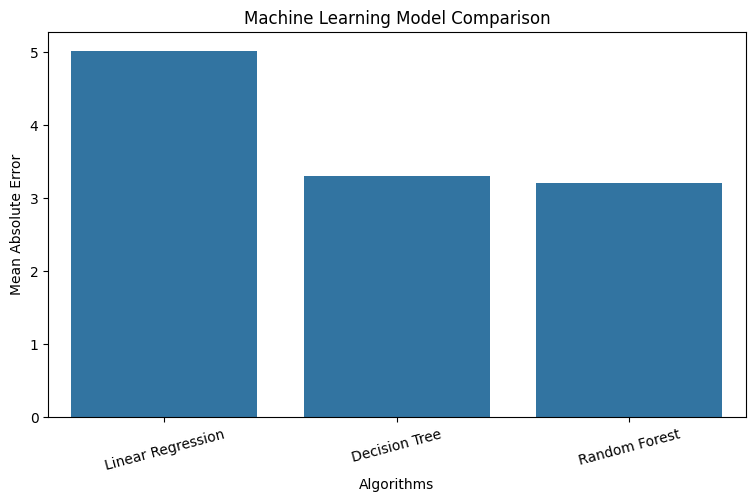

In [ ]:


results_df = pd.DataFrame(results).T

display(results_df)

plt.figure(figsize=(9,5))

sns.barplot(
    x=results_df.index,
    y=results_df["MAE"]
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=15)

plt.show()

In [ ]:


best_model_name = results_df["MAE"].idxmin()

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best Model MAE:",
    round(results_df.loc[best_model_name, "MAE"], 2)
)

Best Model: Random Forest
Best Model MAE: 3.2


In [ ]:


model_data = {
    "model": best_model,
    "model_name": best_model_name,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "categories": {
        col: sorted(X[col].dropna().astype(str).unique().tolist())
        for col in categorical_features
    }
}

with open("food_delivery_model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:


sample = X_test.iloc[[0]].copy()

prediction = best_model.predict(sample)[0]

print("Actual Delivery Time:",
      round(y_test.iloc[0], 2), "Minutes")

print("Predicted Delivery Time:",
      round(prediction, 2), "Minutes")

Actual Delivery Time: 44 Minutes
Predicted Delivery Time: 38.73 Minutes


In [ ]:
# Select several samples from the test set for quick visual verification
samples = X_test.head(5).copy()
actuals = y_test.head(5).values
predictions = best_model.predict(samples)

# Create a comparison table
results_df = pd.DataFrame({
    'Actual Time (Min)': actuals,
    'Predicted Time (Min)': [round(p, 2) for p in predictions],
    'Difference (Min)': [round(abs(a - p), 2) for a, p in zip(actuals, predictions)]
})

print("=== FIRST PREDICTION RESULTS ===")
display(results_df)

=== FIRST PREDICTION RESULTS ===


,Actual Time (Min),Predicted Time (Min),Difference (Min)
0,44,38.73,5.27
1,41,42.78,1.78
2,39,36.06,2.94
3,38,41.09,3.09
4,38,41.81,3.81


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import pickle

# ==========================================
# 1. PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Food Delivery Predictor",
    page_icon="🍔",
    layout="wide"
)

# ==========================================
# 2. CUSTOM DESIGN
# ==========================================

st.markdown("""
<style>

.stApp {
    background-color: #101827;
    color: white;
}

h1 {
    color: #FFB347;
    text-align: center;
}

h2, h3 {

    color: #FFFFFF !important;
}
[data-testid="stWidgetLabel"],
[data-testid="stWidgetLabel"] p,
[data-testid="stWidgetLabel"] span,
[data-testid="stWidgetLabel"] div,
.stNumberInput label,
.stSelectbox label,
.stSlider label {
    color: #FFFFFF !important;
    font-weight: 600 !important;
    font-size: 16px !important;
}
div.stButton > button {
    background-color: #FF8C42;
    color: white;
    border-radius: 10px;
    height: 50px;
    width: 100%;
    font-size: 18px;
    font-weight: bold;
    transition: all 0.2s ease-in-out;
}

div.stButton > button:hover {
    background-color: #FF6B1A;
    transform: translateY(-2px);
    box-shadow: 0 6px 18px rgba(255, 140, 66, 0.45);
}

[data-testid="stMetric"] {
    background-color: #FFFFFF;
    padding: 20px;
    border-radius: 12px;
}

[data-testid="stMetricLabel"],
[data-testid="stMetricValue"] {
    color: #111827 !important;
}

</style>
""", unsafe_allow_html=True)
# ==========================================
# 3. LOAD MODEL
# ==========================================

@st.cache_resource
def load_model():

    with open("food_delivery_model.pkl", "rb") as file:
        return pickle.load(file)

try:
    saved_data = load_model()
    model = saved_data["model"]
    categories = saved_data["categories"]

except FileNotFoundError:
    st.error("Model file not found. Train the model first.")
    st.stop()

# ==========================================
# 4. MAIN TITLE
# ==========================================

st.title("🍔 FOOD DELIVERY TIME PREDICTOR")

st.markdown(
    "<p style='text-align:center;'>"
    "Predict your food delivery time using Machine Learning"
    "</p>",
    unsafe_allow_html=True
)

st.divider()

st.success(
    "Active Model: " + saved_data["model_name"]
)

# ==========================================
# 5. USER INPUT
# ==========================================

st.subheader("📋 Enter Delivery Details")

col1, col2 = st.columns(2)

with col1:

    st.subheader("👨‍🍳 Delivery Information")

    age = st.number_input(
        "Delivery Person Age",
        18, 60, 25
    )

    rating = st.number_input(
        "Delivery Person Rating",
        1.0, 5.0, 4.5, 0.1
    )

    vehicle = st.selectbox(
        "Vehicle Condition",
        [0, 1, 2, 3]
    )

    deliveries = st.selectbox(
        "Multiple Deliveries",
        [1, 2, 3, 4]
    )

    hour = st.slider(
        "Order Time",
        0, 23, 13
    )

    distance = st.number_input(
        "Distance (KM)",
        0.1, 100.0, 5.0, 0.5
    )

with col2:

    st.subheader("🌦️ Environment Information")

    def get_options(column):

        options = categories.get(column, [])

        if not options:
            return ["Unknown"]

        return options

    weather = st.selectbox(
        "Weather Conditions",
        get_options("Weatherconditions")
    )

    traffic = st.selectbox(
        "Road Traffic Density",
        get_options("Road_traffic_density")
    )

    order_type = st.selectbox(
        "Type of Order",
        get_options("Type_of_order")
    )

    vehicle_type = st.selectbox(
        "Type of Vehicle",
        get_options("Type_of_vehicle")
    )

    city = st.selectbox(
        "City",
        get_options("City")
    )

# ==========================================
# 6. PREDICTION
# ==========================================

st.divider()

if st.button("🚀 PREDICT DELIVERY TIME"):

    input_data = pd.DataFrame([{

        "Delivery_person_Age": age,
        "Delivery_person_Ratings": rating,
        "Vehicle_condition": vehicle,
        "multiple_deliveries": deliveries,
        "order_hour": hour,
        "distance_km": distance,

        "Weatherconditions": weather,
        "Road_traffic_density": traffic,
        "Type_of_order": order_type,
        "Type_of_vehicle": vehicle_type,
        "City": city

    }])

    input_data = input_data[saved_data["features"]]

    prediction = model.predict(input_data)[0]

    prediction = max(0, prediction)

    minutes = round(prediction)

    # ======================================
    # 7. DISPLAY RESULT
    # ======================================


    st.divider()
    st.subheader("🎉 YOUR PREDICTION RESULT")

    col_res1, col_res2 = st.columns([2, 1])

    with col_res1:
        st.metric(
            "Estimated Delivery Time",
            f"{minutes} Minutes"
        )

    with col_res2:
        if minutes <= 25:
            st.metric("Delivery Vibe", "🚀 Rocket Speed")
        elif minutes <= 40:
            st.metric("Delivery Vibe", "🛵 Smooth Cruise")
        else:
            st.metric("Delivery Vibe", "🐢 Scenic Route")

    # Visual ETA Progress Bar
    progress_val = min(minutes / 60.0, 1.0)
    st.progress(progress_val, text=f"Kitchen-to-Doorstep Meter: {minutes} / 60 mins")

    # Playful conditional reactions
    if minutes <= 20:
        st.balloons()
        st.success(f"⚡ {minutes} mins?! The chef probably started cooking before you even clicked order!")
    elif minutes <= 30:
        st.balloons()
        st.success(f"🍕 Arriving in {minutes} minutes! Just enough time to pick a movie and grab plates.")
    elif minutes <= 45:
        st.info(f"🚴 Expected in {minutes} minutes. Your rider is dodging traffic like a pro!")
    else:
        st.snow()
        st.warning(f"⏳ {minutes} minutes! Traffic or weather is playing hard mode—maybe grab a small snack while you wait.")

    # Collapsible Order Receipt
    with st.expander("🧾 View Order & Route Receipt"):
        st.write(f"**📍 Distance:** {distance} km | **🏙️ City:** {city}")
        st.write(f"**🌦️ Weather:** {weather} | **🚦 Traffic:** {traffic}")
        st.write(f"**🛵 Rider Rating:** {rating} ⭐ ({vehicle_type})")
        st.write(f"**📦 Order Type:** {order_type} (Batch size: {deliveries})")

    st.caption(
        "This is an estimated time generated by a machine learning model."
    )
# ==========================================
# 8. FOOTER
# ==========================================

st.divider()

st.markdown(
    "<p style='text-align:center;'>"
    "Made with ❤️ using Python, Scikit-learn and Streamlit"
    "</p>",
    unsafe_allow_html=True
)

Writing app.py


In [ ]:


!pip install -q streamlit pyngrok

In [ ]:


from pyngrok import ngrok

ngrok.set_auth_token("YOUR_NGROK_AUTH_TOKEN")

public_url = ngrok.connect(port="8501

print("Ngrok connected successfully!")

Ngrok connected successfully!


In [ ]:
from pyngrok import ngrok
ngrok.kill()

In [ ]:
import os
import time
from pyngrok import ngrok

# 1. Forcefully kill any running local processes on ports
os.system("pkill -9 streamlit")
os.system("pkill -9 ngrok")
time.sleep(2)

# 2. Programmatically close active cloud tunnels to clear ERR_NGROK_334
try:
    for tunnel in ngrok.get_tunnels():
        ngrok.disconnect(tunnel.public_url)
    ngrok.kill()
except Exception:
    pass

time.sleep(1)

# 3. Start Streamlit in the background and pipe output
print("Starting Streamlit server...")
os.system("nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &")
time.sleep(4)

# 4. Connect clean ngrok tunnel and explicitly print URL
try:
    public_url = ngrok.connect(8501)
    print("\n=========================================")
    print("🚀 YOUR WEB APPLICATION IS READY!")
    print("Click the link below to open your app:")
    print(public_url)
    print("=========================================\n")
except Exception as e:
    print("Error connecting to ngrok:", e)

Starting Streamlit server...

🚀 YOUR WEB APPLICATION IS READY!
Click the link below to open your app:
NgrokTunnel: "https://octopus-starry-buggy.ngrok-free.dev" -> "http://localhost:8501"



In [ ]:
import os
import time
from pyngrok import ngrok

# Kill any existing streamlit or ngrok processes to prevent port conflicts
os.system("pkill streamlit")
os.system("pkill ngrok")

time.sleep(2)

# Run streamlit in the background, redirecting output to a log file
os.system("nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &")

time.sleep(3)

# Establish ngrok tunnel
try:
    public_url = ngrok.connect(8501)
    print("\n=========================================")
    print("🚀 YOUR WEB APPLICATION IS READY!")
    print("Click the link below to open your app:")
    print(public_url)
    print("=========================================\n")
except Exception as e:
    print("Error connecting to ngrok:", e)



🚀 YOUR WEB APPLICATION IS READY!
Click the link below to open your app:
NgrokTunnel: "https://octopus-starry-buggy.ngrok-free.dev" -> "http://localhost:8501"



In [ ]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn

Writing requirements.txt


In [ ]:
from google.colab import files

files.download("app.py")
files.download("food_delivery_model.pkl")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>